# Homework 8

## 1. Supervised, Semi-Supervised, and Unsupervised Learning

### 1(a) Load the Breast Cancer Data

I used the Breast Cancer Wisconsin Diagnostic dataset. I used the 30 measurements as features and left out the patient ID. I set benign to 0 and malignant to 1.

In [1]:
import pandas as pd

breast_cancer = pd.read_csv("data/wdbc.data", header=None)

X = breast_cancer.iloc[:, 2:].copy()
y = breast_cancer.iloc[:, 1].map({"B": 0, "M": 1}).rename("diagnosis")

print(f"Feature shape: {X.shape}")
print(y.value_counts().sort_index())
print(f"Missing feature values: {X.isna().sum().sum()}")

Feature shape: (569, 30)
diagnosis
0    357
1    212
Name: count, dtype: int64
Missing feature values: 0


### 1(b)(i) Supervised Learning

I used a stratified split to put about 20% of each class in the test set. I used StandardScaler and a linear SVM with an L1 penalty. I picked C with 5-fold cross-validation on the training set.

In [28]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

def fit_l1_svm(features, labels, *, tol=1e-4, c_values=(0.001, 0.01, 0.1, 1, 10)):
    pipeline = make_pipeline(
        StandardScaler(),
        LinearSVC(penalty="l1", dual=False, max_iter=100000, random_state=42, tol=tol)
    )
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    search = GridSearchCV(
        pipeline,
        {"linearsvc__C": c_values},
        scoring="accuracy",
        cv=cv,
        error_score="raise"
    )
    return search.fit(features, labels)

def classification_scores(y_true, y_pred, y_score):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "AUC": roc_auc_score(y_true, y_score)
    }

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

supervised_model = fit_l1_svm(X_train, y_train)

train_predictions = supervised_model.predict(X_train)
test_predictions = supervised_model.predict(X_test)
train_decisions = supervised_model.decision_function(X_train)
test_decisions = supervised_model.decision_function(X_test)

split_counts = pd.DataFrame({
    "Train": y_train.value_counts().sort_index(),
    "Test": y_test.value_counts().sort_index()
}).rename(index={0: "Benign", 1: "Malignant"})

supervised_scores = pd.DataFrame(
    [
        classification_scores(y_train, train_predictions, train_decisions),
        classification_scores(y_test, test_predictions, test_decisions)
    ],
    index=["Train", "Test"]
)

print(f"Best C: {supervised_model.best_params_['linearsvc__C']}")
display(split_counts)
display(supervised_scores.round(4))

Best C: 1


,Train,Test
diagnosis,,
Benign,285,72
Malignant,170,42


,Accuracy,Precision,Recall,F1,AUC
Train,0.9890,0.9940,0.9765,0.9852,0.9989
Test,0.9561,0.9744,0.9048,0.9383,0.9871


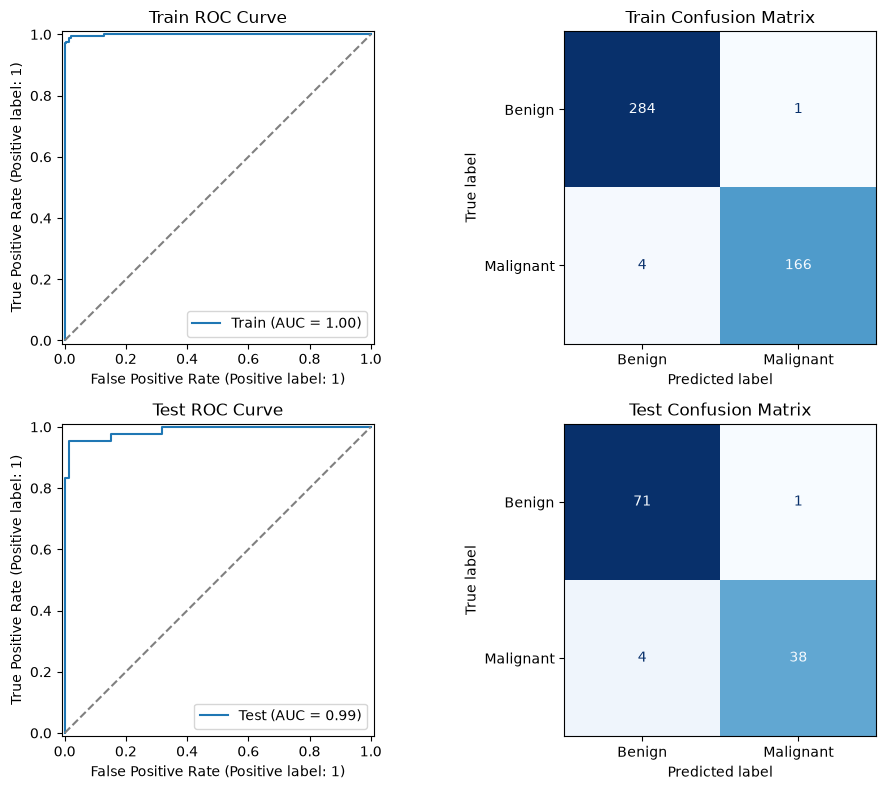

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for row, name, labels, predictions, scores in [
    (0, "Train", y_train, train_predictions, train_decisions),
    (1, "Test", y_test, test_predictions, test_decisions)
]:
    RocCurveDisplay.from_predictions(labels, scores, name=name, ax=axes[row, 0])
    axes[row, 0].plot([0, 1], [0, 1], linestyle="--", color="gray")
    axes[row, 0].set_title(f"{name} ROC Curve")

    ConfusionMatrixDisplay.from_predictions(
        labels,
        predictions,
        labels=[0, 1],
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=axes[row, 1]
    )
    axes[row, 1].set_title(f"{name} Confusion Matrix")

fig.tight_layout()
plt.show()

In [7]:
simulation_seeds = range(42, 72)
supervised_records = []

for run, seed in enumerate(simulation_seeds, start=1):
    X_train_run, X_test_run, y_train_run, y_test_run = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=seed
    )
    model = fit_l1_svm(X_train_run, y_train_run)

    for name, features, labels in [
        ("Train", X_train_run, y_train_run),
        ("Test", X_test_run, y_test_run)
    ]:
        scores = classification_scores(
            labels, model.predict(features), model.decision_function(features)
        )
        supervised_records.append({"Run": run, "Set": name, **scores})

supervised_results = pd.DataFrame(supervised_records)
supervised_average = (
    supervised_results.drop(columns="Run")
    .groupby("Set")
    .mean()
    .reindex(["Train", "Test"])
)

display(supervised_average.round(4))

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Train,0.9868,0.9932,0.9714,0.9821,0.9975
Test,0.9737,0.9783,0.9500,0.9636,0.9941


I ran the experiment 30 times. The average test accuracy was 0.9737, and the average test AUC was 0.9941. The ROC curves and confusion matrices show the results from the first run.

### 1(b)(ii) Semi-Supervised Learning

I started with about half of each class labeled. I picked C with 5-fold cross-validation on the labeled data. Then I picked the unlabeled point farthest from the SVM boundary. I used the model's prediction as its pseudo-label and trained the model again. I repeated this until every point had a label.

In [8]:
import numpy as np

def fit_self_training(features, labels, seed):
    labeled_indices, unlabeled_indices = train_test_split(
        np.arange(len(labels)),
        train_size=0.50,
        stratify=labels,
        random_state=seed
    )

    training_labels = labels.iloc[labeled_indices].to_numpy()
    initial_counts = labels.iloc[labeled_indices].value_counts().sort_index()
    model = fit_l1_svm(
        features.iloc[labeled_indices], training_labels
    ).best_estimator_

    while unlabeled_indices.size > 0:
        decisions = model.decision_function(features.iloc[unlabeled_indices])
        position = np.argmax(np.abs(decisions))
        new_index = unlabeled_indices[position]
        new_label = model.predict(features.iloc[[new_index]])[0]

        labeled_indices = np.append(labeled_indices, new_index)
        training_labels = np.append(training_labels, new_label)
        unlabeled_indices = np.delete(unlabeled_indices, position)

        model.fit(features.iloc[labeled_indices], training_labels)

    return model, initial_counts

In [9]:
semi_model, initial_counts = fit_self_training(X_train, y_train, seed=42)

semi_train_predictions = semi_model.predict(X_train)
semi_test_predictions = semi_model.predict(X_test)
semi_train_decisions = semi_model.decision_function(X_train)
semi_test_decisions = semi_model.decision_function(X_test)

semi_scores = pd.DataFrame(
    [
        classification_scores(y_train, semi_train_predictions, semi_train_decisions),
        classification_scores(y_test, semi_test_predictions, semi_test_decisions)
    ],
    index=["Train", "Test"]
)

print(f"Initial labeled points: {initial_counts.sum()}")
print(f"Pseudo-labeled points: {len(y_train) - initial_counts.sum()}")
print(f"Best C: {semi_model.named_steps['linearsvc'].C}")
display(initial_counts.rename(index={0: "Benign", 1: "Malignant"}))
display(semi_scores.round(4))

Initial labeled points: 227
Pseudo-labeled points: 228
Best C: 0.1


diagnosis
Benign       142
Malignant     85
Name: count, dtype: int64

,Accuracy,Precision,Recall,F1,AUC
Train,0.9780,0.9762,0.9647,0.9704,0.9934
Test,0.9649,0.9750,0.9286,0.9512,0.9967


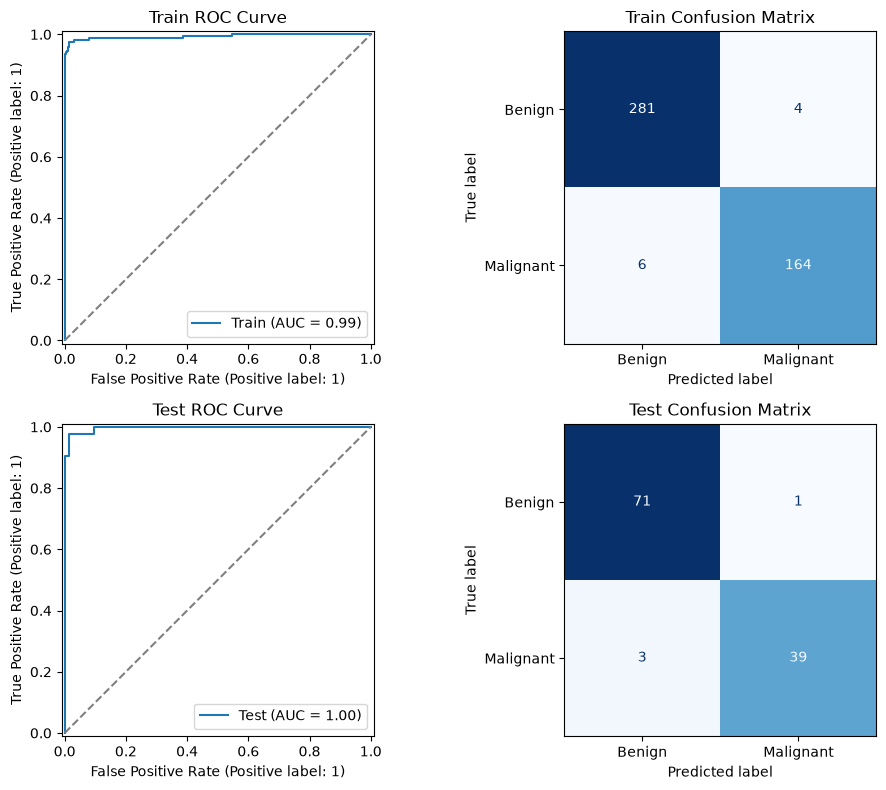

In [10]:
def plot_classification_run(train_results, test_results):
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))

    for row, name, results in [
        (0, "Train", train_results),
        (1, "Test", test_results)
    ]:
        labels, predictions, scores = results
        RocCurveDisplay.from_predictions(labels, scores, name=name, ax=axes[row, 0])
        axes[row, 0].plot([0, 1], [0, 1], linestyle="--", color="gray")
        axes[row, 0].set_title(f"{name} ROC Curve")

        ConfusionMatrixDisplay.from_predictions(
            labels,
            predictions,
            labels=[0, 1],
            display_labels=["Benign", "Malignant"],
            cmap="Blues",
            colorbar=False,
            ax=axes[row, 1]
        )
        axes[row, 1].set_title(f"{name} Confusion Matrix")

    fig.tight_layout()
    plt.show()

plot_classification_run(
    (y_train, semi_train_predictions, semi_train_decisions),
    (y_test, semi_test_predictions, semi_test_decisions)
)

In [11]:
semi_records = []

for run, seed in enumerate(simulation_seeds, start=1):
    X_train_run, X_test_run, y_train_run, y_test_run = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=seed
    )
    model, _ = fit_self_training(X_train_run, y_train_run, seed)

    for name, features, labels in [
        ("Train", X_train_run, y_train_run),
        ("Test", X_test_run, y_test_run)
    ]:
        scores = classification_scores(
            labels, model.predict(features), model.decision_function(features)
        )
        semi_records.append({"Run": run, "Set": name, **scores})

semi_results = pd.DataFrame(semi_records)
semi_average = (
    semi_results.drop(columns="Run")
    .groupby("Set")
    .mean()
    .reindex(["Train", "Test"])
)

display(semi_average.round(4))

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Train,0.9751,0.9827,0.9506,0.9661,0.9945
Test,0.9655,0.9666,0.9413,0.9526,0.9922


Across 30 runs, the average test accuracy was 0.9655 and the average test AUC was 0.9922. The ROC curves and confusion matrices show the first run.

### 1(b)(iii) K-means Clustering

I scaled the features using the training set. I ran K-means with two clusters and 30 random starts. I kept the result with the lowest inertia. This lowered the chance of getting stuck in a poor local minimum.

I used the 30 training points closest to each center to pick its class by majority vote. I assigned each point to its nearest center. For the ROC curve, I used softmax on the negative distances to get a score for the malignant class.

In [12]:
from scipy.special import softmax
from sklearn.cluster import KMeans

def fit_kmeans(features, labels, seed):
    model = make_pipeline(
        StandardScaler(),
        KMeans(n_clusters=2, init="random", n_init=30, random_state=seed)
    )
    model.fit(features)

    distances = model.transform(features)
    cluster_labels = []

    for cluster in range(2):
        nearest = np.argsort(distances[:, cluster])[:30]
        majority_label = labels.iloc[nearest].value_counts().idxmax()
        cluster_labels.append(majority_label)

    return model, np.array(cluster_labels)

def classify_kmeans(model, cluster_labels, features):
    distances = model.transform(features)
    predictions = cluster_labels[distances.argmin(axis=1)]
    cluster_scores = softmax(-distances, axis=1)
    scores = cluster_scores[:, cluster_labels == 1].sum(axis=1)
    return predictions, scores

Cluster labels: [0, 1]
Inertia: 9254.83


,Accuracy,Precision,Recall,F1,AUC
Train,0.9077,0.9051,0.8412,0.8720,0.9709
Test,0.8947,0.9167,0.7857,0.8462,0.9775


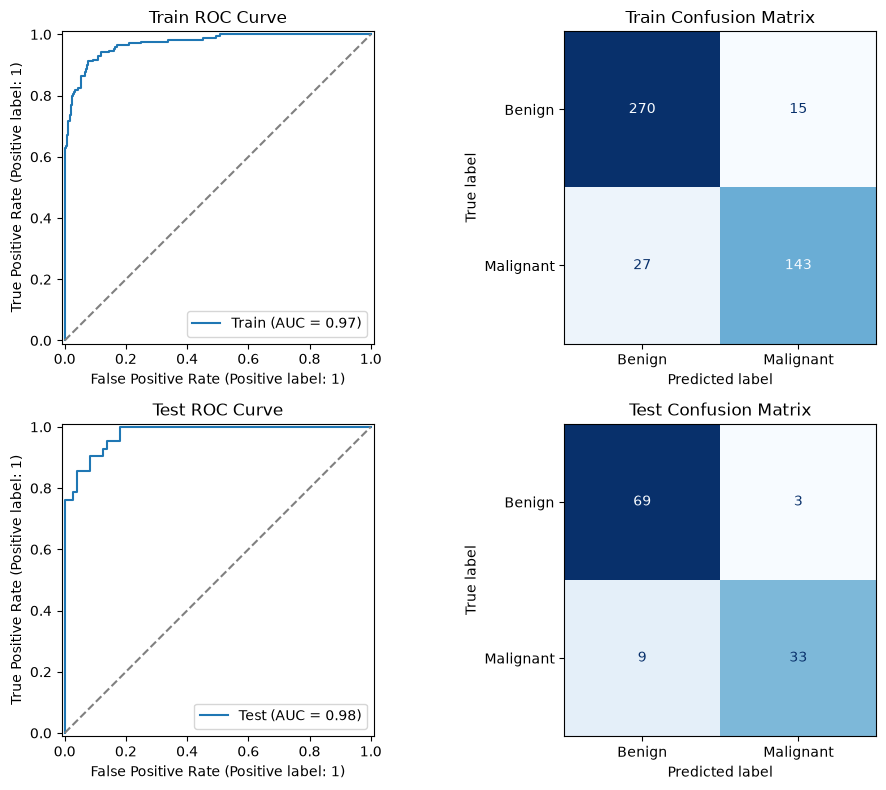

In [13]:
kmeans_model, kmeans_cluster_labels = fit_kmeans(X_train, y_train, seed=42)

kmeans_train_predictions, kmeans_train_scores = classify_kmeans(
    kmeans_model, kmeans_cluster_labels, X_train
)
kmeans_test_predictions, kmeans_test_scores = classify_kmeans(
    kmeans_model, kmeans_cluster_labels, X_test
)

kmeans_scores = pd.DataFrame(
    [
        classification_scores(y_train, kmeans_train_predictions, kmeans_train_scores),
        classification_scores(y_test, kmeans_test_predictions, kmeans_test_scores)
    ],
    index=["Train", "Test"]
)

print(f"Cluster labels: {kmeans_cluster_labels.tolist()}")
print(f"Inertia: {kmeans_model.named_steps['kmeans'].inertia_:.2f}")
display(kmeans_scores.round(4))

plot_classification_run(
    (y_train, kmeans_train_predictions, kmeans_train_scores),
    (y_test, kmeans_test_predictions, kmeans_test_scores)
)

In [14]:
kmeans_records = []

for run, seed in enumerate(simulation_seeds, start=1):
    X_train_run, X_test_run, y_train_run, y_test_run = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=seed
    )
    model, cluster_labels = fit_kmeans(X_train_run, y_train_run, seed)

    for name, features, labels in [
        ("Train", X_train_run, y_train_run),
        ("Test", X_test_run, y_test_run)
    ]:
        predictions, scores = classify_kmeans(model, cluster_labels, features)
        metrics = classification_scores(labels, predictions, scores)
        kmeans_records.append({"Run": run, "Set": name, **metrics})

kmeans_results = pd.DataFrame(kmeans_records)
kmeans_average = (
    kmeans_results.drop(columns="Run")
    .groupby("Set")
    .mean()
    .reindex(["Train", "Test"])
)

display(kmeans_average.round(4))

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Train,0.9100,0.9245,0.8271,0.8728,0.9747
Test,0.9135,0.9199,0.8389,0.8764,0.9753


Across 30 runs, the average test accuracy was 0.9135, and the average test AUC was 0.9753. In the first run, K-means found 33 of the 42 malignant cases in the test set.

### 1(b)(iv) Spectral Clustering

Spectral clustering uses a graph to connect similar points. I used an RBF kernel with gamma set to 1. The graph Laplacian helped form two clusters.

I scaled the features using the training set and clipped the scaled values to the range from 0 to 1. I used fit_predict on the training and test features together. This is called transductive clustering. I used only the training labels to vote on each cluster's class. For ROC and AUC, I used the share of malignant votes in each cluster as its score.

[Reference: scikit-learn SpectralClustering documentation](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html)

In [15]:
from sklearn.cluster import SpectralClustering
from sklearn.preprocessing import MinMaxScaler

def fit_spectral_clustering(X_train, X_test, y_train, seed):
    scaler = MinMaxScaler(clip=True)
    train_scaled = scaler.fit_transform(X_train)
    test_scaled = scaler.transform(X_test)
    all_features = np.vstack([train_scaled, test_scaled])

    model = SpectralClustering(
        n_clusters=2,
        affinity="rbf",
        gamma=1,
        assign_labels="kmeans",
        n_init=30,
        random_state=seed
    )
    clusters = model.fit_predict(all_features)
    train_clusters = clusters[:len(X_train)]
    test_clusters = clusters[len(X_train):]

    cluster_votes = np.array([
        y_train.to_numpy()[train_clusters == cluster].mean()
        for cluster in range(2)
    ])
    cluster_labels = (cluster_votes > 0.5).astype(int)

    train_results = (cluster_labels[train_clusters], cluster_votes[train_clusters])
    test_results = (cluster_labels[test_clusters], cluster_votes[test_clusters])

    return train_results, test_results, cluster_votes

0    0.1778
1    0.9732
Name: Malignant vote fraction, dtype: float64

,Accuracy,Precision,Recall,F1,AUC
Train,0.8593,0.9732,0.6412,0.7730,0.8153
Test,0.8596,1.0000,0.6190,0.7647,0.8095


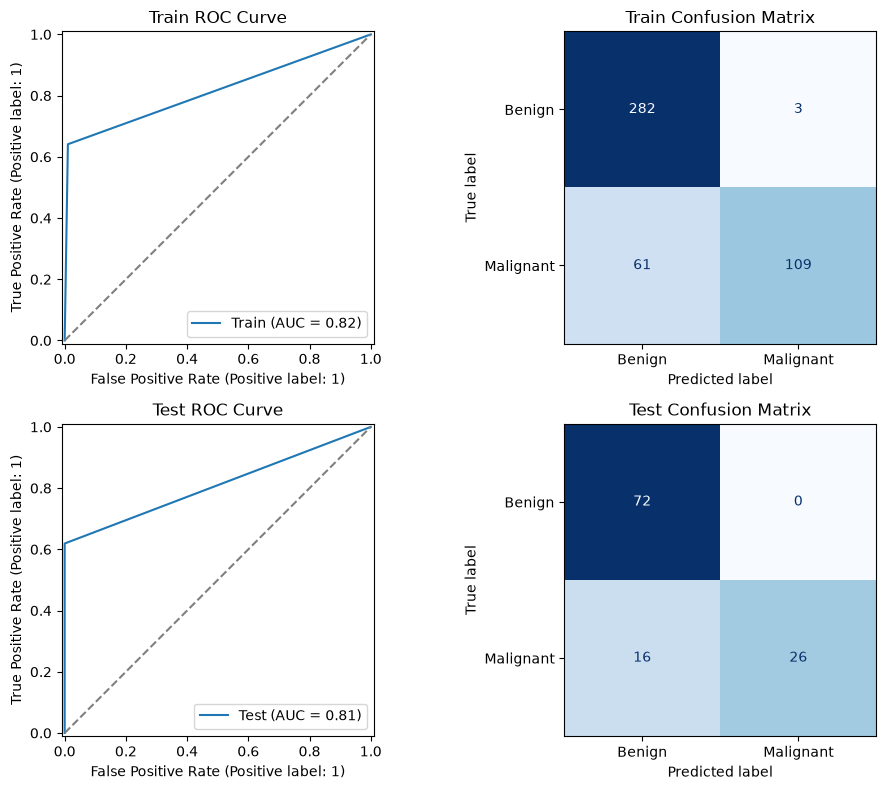

In [16]:
spectral_train, spectral_test, spectral_votes = fit_spectral_clustering(
    X_train, X_test, y_train, seed=42
)

spectral_scores = pd.DataFrame(
    [
        classification_scores(y_train, *spectral_train),
        classification_scores(y_test, *spectral_test)
    ],
    index=["Train", "Test"]
)

display(pd.Series(spectral_votes, name="Malignant vote fraction").round(4))
display(spectral_scores.round(4))

plot_classification_run(
    (y_train, *spectral_train),
    (y_test, *spectral_test)
)

In [17]:
spectral_records = []

for run, seed in enumerate(simulation_seeds, start=1):
    X_train_run, X_test_run, y_train_run, y_test_run = train_test_split(
        X, y, test_size=0.20, stratify=y, random_state=seed
    )
    train_output, test_output, _ = fit_spectral_clustering(
        X_train_run, X_test_run, y_train_run, seed
    )

    for name, labels, output in [
        ("Train", y_train_run, train_output),
        ("Test", y_test_run, test_output)
    ]:
        metrics = classification_scores(labels, *output)
        spectral_records.append({"Run": run, "Set": name, **metrics})

spectral_results = pd.DataFrame(spectral_records)
spectral_average = (
    spectral_results.drop(columns="Run")
    .groupby("Set")
    .mean()
    .reindex(["Train", "Test"])
)

display(spectral_average.round(4))

,Accuracy,Precision,Recall,F1,AUC
Set,,,,,
Train,0.8527,0.9819,0.6175,0.7573,0.8053
Test,0.8699,0.9840,0.6579,0.7865,0.8257


### 1(b)(v) Comparison of the Four Methods

In [18]:
comparison = pd.concat(
    {
        "Supervised SVM": supervised_average,
        "Semi-Supervised SVM": semi_average,
        "K-means": kmeans_average,
        "Spectral Clustering": spectral_average
    },
    names=["Method", "Set"]
)

display(comparison.round(4))

Accuracy  Precision  Recall      F1     AUC
Method              Set                                               
Supervised SVM      Train    0.9868     0.9932  0.9714  0.9821  0.9975
                    Test     0.9737     0.9783  0.9500  0.9636  0.9941
Semi-Supervised SVM Train    0.9751     0.9827  0.9506  0.9661  0.9945
                    Test     0.9655     0.9666  0.9413  0.9526  0.9922
K-means             Train    0.9100     0.9245  0.8271  0.8728  0.9747
                    Test     0.9135     0.9199  0.8389  0.8764  0.9753
Spectral Clustering Train    0.8527     0.9819  0.6175  0.7573  0.8053
                    Test     0.8699     0.9840  0.6579  0.7865  0.8257

The supervised SVM had the highest average test accuracy (0.9737) and AUC (0.9941). The semi-supervised SVM was close, with an average test accuracy of 0.9655. It started with only half of the training labels.

K-means had higher test accuracy than spectral clustering (0.9135 vs. 0.8699). Spectral clustering had the highest test precision (0.9840) and the lowest test recall (0.6579). This means it was usually right when it predicted malignant, but it missed more malignant cases than the other methods.

All four methods used the same 30 splits. Spectral clustering used the test features in its graph and used only the training labels to name the clusters.

## 2. Active Learning Using Support Vector Machines

### 2(a) Load and Split the Banknote Data

I loaded 1,372 banknote samples. Each sample has four features and one class label. I randomly picked 472 samples for the test set and used the other 900 as the training pool. Both learning methods used the same split.|

In [19]:
banknote = pd.read_csv(
    "data/data_banknote_authentication.txt",
    header=None,
    names=["variance", "skewness", "kurtosis", "entropy", "class"]
)

X_bank = banknote.drop(columns="class")
y_bank = banknote["class"]

X_bank_train, X_bank_test, y_bank_train, y_bank_test = train_test_split(
    X_bank, y_bank, test_size=472, random_state=42
)

bank_split_counts = pd.DataFrame({
    "Train": y_bank_train.value_counts().sort_index(),
    "Test": y_bank_test.value_counts().sort_index()
})

print(f"Full dataset: {banknote.shape}")
print(f"Training features: {X_bank_train.shape}")
print(f"Test features: {X_bank_test.shape}")
print(f"Missing values: {banknote.isna().sum().sum()}")
display(bank_split_counts)

Full dataset: (1372, 5)
Training features: (900, 4)
Test features: (472, 4)
Missing values: 0


,Train,Test
class,,
0,496,266
1,404,206


### 2(b)(i) Passive Learning

I randomly picked five samples from each class to make a starting set of 10. This gave both classes to each of the five validation folds. At each step, I added 10 random samples from the remaining training pool. I used 5-fold cross-validation to pick C for each L1 SVM. I recorded the test error at each training size.

In [29]:
def initial_banknote_pool(labels, rng):
    label_values = labels.to_numpy()
    return np.concatenate([
        rng.choice(np.flatnonzero(label_values == label), size=5, replace=False)
        for label in (0, 1)
    ])

def passive_learning_run(X_pool, y_pool, X_test_data, y_test_data, seed):
    rng = np.random.default_rng(seed)
    initial_pool = initial_banknote_pool(y_pool, rng)
    remaining = np.setdiff1d(np.arange(len(y_pool)), initial_pool)
    sample_order = np.concatenate([initial_pool, rng.permutation(remaining)])

    pool_features = X_pool.to_numpy()
    pool_labels = y_pool.to_numpy()
    test_features = X_test_data.to_numpy()
    test_labels = y_test_data.to_numpy()
    test_errors = []

    for size in range(10, len(y_pool) + 1, 10):
        selected = np.sort(sample_order[:size])
        model = fit_l1_svm(
            pool_features[selected],
            pool_labels[selected],
            tol=1e-3,
            c_values=(0.001, 0.02, 0.1, 1, 10)
        )
        test_errors.append(1.0 - model.score(test_features, test_labels))

    return np.array(test_errors)

In [25]:
banknote_sizes = np.arange(10, len(y_bank_train) + 1, 10)

passive_first_errors = passive_learning_run(
    X_bank_train, y_bank_train, X_bank_test, y_bank_test, seed=42
)

passive_first_run = pd.DataFrame({
    "Training Size": banknote_sizes,
    "Test Error": passive_first_errors
})

print(f"Number of test errors: {len(passive_first_run)}")
display(pd.concat([passive_first_run.head(5), passive_first_run.tail(1)]).round(4))

Number of test errors: 90


,Training Size,Test Error
0,10,0.0191
1,20,0.0106
2,30,0.0106
3,40,0.0148
4,50,0.0127
89,900,0.0106


### 2(b)(ii) Active Learning

I started with the same 10 samples as passive learning. After each fit, I picked the 10 remaining samples with the smallest absolute SVM scores. These points were closest to the SVM boundary. I added them with their true labels and trained the model again. I recorded the test error at each training size.

In [30]:
def active_learning_run(X_pool, y_pool, X_test_data, y_test_data, seed):
    rng = np.random.default_rng(seed)
    selected = np.sort(initial_banknote_pool(y_pool, rng))
    remaining = rng.permutation(np.setdiff1d(np.arange(len(y_pool)), selected))

    pool_features = X_pool.to_numpy()
    pool_labels = y_pool.to_numpy()
    test_features = X_test_data.to_numpy()
    test_labels = y_test_data.to_numpy()
    test_errors = []

    for size in range(10, len(y_pool) + 1, 10):
        model = fit_l1_svm(
            pool_features[selected],
            pool_labels[selected],
            tol=1e-3,
            c_values=(0.001, 0.02, 0.1, 1, 10)
        )
        test_errors.append(1.0 - model.score(test_features, test_labels))

        if size < len(y_pool):
            margins = np.abs(model.decision_function(pool_features[remaining]))
            closest = np.argsort(margins, kind="stable")[:10]
            selected = np.sort(np.concatenate([selected, remaining[closest]]))
            remaining = np.delete(remaining, closest)

    return np.array(test_errors)

In [27]:
active_first_errors = active_learning_run(
    X_bank_train, y_bank_train, X_bank_test, y_bank_test, seed=42
)

banknote_first_run = pd.DataFrame({
    "Training Size": banknote_sizes,
    "Passive Test Error": passive_first_errors,
    "Active Test Error": active_first_errors
})

print(f"Number of active test errors: {len(active_first_errors)}")
display(pd.concat([banknote_first_run.head(5), banknote_first_run.tail(1)]).round(4))

Number of active test errors: 90


,Training Size,Passive Test Error,Active Test Error
0,10,0.0191,0.0191
1,20,0.0106,0.0297
2,30,0.0106,0.0127
3,40,0.0148,0.0169
4,50,0.0127,0.0085
89,900,0.0106,0.0106


### 2(c) Monte Carlo Learning Curves

I ran both methods 50 times. In each run, they started with the same 10 samples. I averaged the test errors at each training size and plotted both learning curves.

In [32]:
from joblib import Parallel, delayed, parallel_config

def run_banknote_pair(seed):
    passive = passive_learning_run(
        X_bank_train, y_bank_train, X_bank_test, y_bank_test, seed
    )
    active = active_learning_run(
        X_bank_train, y_bank_train, X_bank_test, y_bank_test, seed
    )
    return passive, active

with parallel_config(backend="loky", inner_max_num_threads=1):
    banknote_runs = Parallel(n_jobs=4, verbose=10)(
        delayed(run_banknote_pair)(seed) for seed in range(42, 92)
    )

passive_errors = np.stack([passive for passive, _ in banknote_runs])
active_errors = np.stack([active for _, active in banknote_runs])

print(f"Passive error matrix: {passive_errors.shape}")
print(f"Active error matrix: {active_errors.shape}")

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:   21.7s
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:   33.9s
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:   55.4s
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  1.2min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed:  1.7min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  2.1min


Passive error matrix: (50, 90)
Active error matrix: (50, 90)


[Parallel(n_jobs=4)]: Done  50 out of  50 | elapsed:  2.4min finished


,Training Size,Passive Test Error,Active Test Error
0,10,0.1391,0.1391
1,20,0.0669,0.0460
4,50,0.0253,0.0135
9,100,0.0182,0.0111
19,200,0.0136,0.0110
39,400,0.0114,0.0111
89,900,0.0106,0.0106


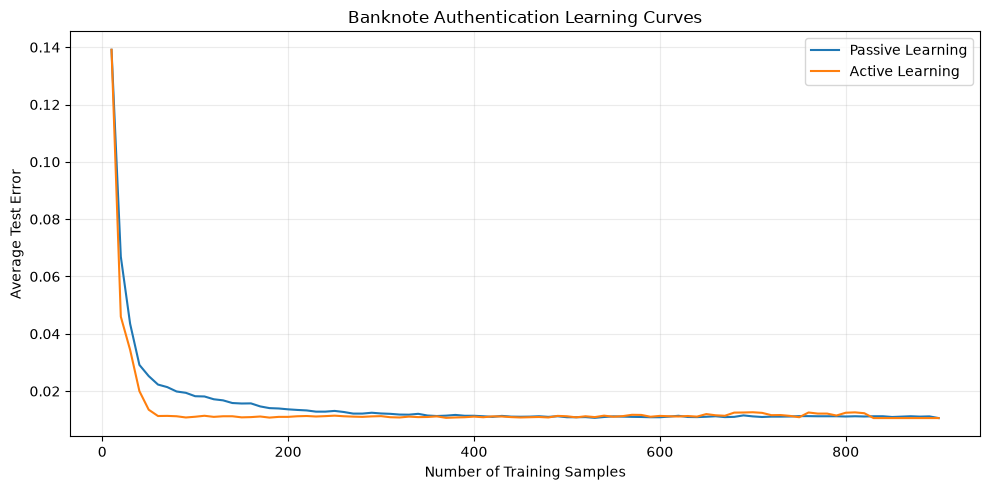

In [33]:
banknote_curve = pd.DataFrame({
    "Training Size": banknote_sizes,
    "Passive Test Error": passive_errors.mean(axis=0),
    "Active Test Error": active_errors.mean(axis=0)
})

display(banknote_curve[
    banknote_curve["Training Size"].isin([10, 20, 50, 100, 200, 400, 900])
].round(4))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(
    banknote_curve["Training Size"],
    banknote_curve["Passive Test Error"],
    label="Passive Learning"
)
ax.plot(
    banknote_curve["Training Size"],
    banknote_curve["Active Test Error"],
    label="Active Learning"
)
ax.set_xlabel("Number of Training Samples")
ax.set_ylabel("Average Test Error")
ax.set_title("Banknote Authentication Learning Curves")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

Active learning had a lower average test error when the training set was small. At 50 samples, its test error was 0.0135. Passive learning had a test error of 0.0253 at the same size. The two curves got closer as the training set grew. At 900 samples, both methods used the full training pool and had the same test error of 0.0106.